In [1]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../data/raw")

df = pd.read_csv(DATA_DIR / "ir_train.csv")
df["departure_date"] = pd.to_datetime(df["departure_date"])

model_df = df.sort_values("departure_date").reset_index(drop=True)

train_df = model_df[
    model_df["departure_date"].dt.year <= 2022
].copy()

val_df = model_df[
    model_df["departure_date"].dt.year == 2023
].copy()

test_df = model_df[
    model_df["departure_date"].dt.year == 2024
].copy()

print("Data loaded successfully!")
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Data loaded successfully!
Training: (1070215, 45)
Validation: (215538, 45)
Test: (214247, 45)


In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

# Resolve the path from the notebook's working directory
CSV_PATH = Path("../data/raw/ir_train.csv")

# Keep only the columns needed for the first experiment
features = [
    "train_type",
    "year",
    "month",
    "day_of_week",
    "departure_hour",
    "is_weekend",
    "is_night_departure",
    "is_peak_hour",
    "is_festival_season",
    "season",
    "zone",
    "source_station_category",
    "destination_station_category",
    "distance_km",
    "num_scheduled_stops",
    "scheduled_travel_hours",
    "track_doubled",
    "is_hdn_route",
    "traction_type",
    "is_electrified",
    "psr_count",
    "is_circular_route",
    "is_monsoon_season",
    "is_fog_risk",
    "fog_risk_score",
    "zone_fog_index",
    "zone_congestion_index",
    "season_severity_score",
    "loco_age_years",
    "coach_age_years",
    "has_lhb_coaches",
    "is_rake_shared",
    "maintenance_score",
    "seat_utilisation_pct",
    "is_overloaded",
    "late_incoming_rake",
    "is_special_train",
    "route_historical_ontime_pct",
]

usecols = ["departure_date", "delay_minutes"] + features

# Collect small samples from each chronological split
samples = {"train": [], "val": [], "test": []}

for chunk in pd.read_csv(
    CSV_PATH,
    usecols=usecols,
    chunksize=100_000,
):
    years = pd.to_numeric(chunk["year"], errors="coerce")

    # Sample training rows from 2018–2022
    train_chunk = chunk.loc[years <= 2022]
    if len(train_chunk):
        samples["train"].append(
            train_chunk.sample(
                n=min(5_000, len(train_chunk)),
                random_state=42,
            )
        )

    # Sample validation rows from 2023
    val_chunk = chunk.loc[years == 2023]
    if len(val_chunk):
        samples["val"].append(
            val_chunk.sample(
                n=min(2_000, len(val_chunk)),
                random_state=42,
            )
        )

    # Keep 2024 separate for final testing
    test_chunk = chunk.loc[years == 2024]
    if len(test_chunk):
        samples["test"].append(
            test_chunk.sample(
                n=min(2_000, len(test_chunk)),
                random_state=42,
            )
        )

train_df = pd.concat(samples["train"], ignore_index=True)
val_df = pd.concat(samples["val"], ignore_index=True)
test_df = pd.concat(samples["test"], ignore_index=True)

print("Sampled dataset sizes:")
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nMean delay:")
print("Train:", train_df["delay_minutes"].mean())
print("Validation:", val_df["delay_minutes"].mean())
print("Test:", test_df["delay_minutes"].mean())


Sampled dataset sizes:
Train: (75000, 40)
Validation: (30000, 40)
Test: (30000, 40)

Mean delay:
Train: 97.56564
Validation: 97.55893333333333
Test: 97.93426666666667


In [2]:

# Separate features and target
X_train = train_df[features]
y_train = train_df["delay_minutes"].astype(float)

X_val = val_df[features]
y_val = val_df["delay_minutes"].astype(float)

# Identify categorical features
categorical = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric = [
    c for c in features if c not in categorical
]

# Force sparse output to avoid a large dense encoded matrix
preprocessor = ColumnTransformer(
    [
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True,
            ),
            categorical,
        ),
        ("num", "passthrough", numeric),
    ],
    sparse_threshold=1.0,
)

X_train_enc = preprocessor.fit_transform(X_train)
X_val_enc = preprocessor.transform(X_val)

print("Encoded training shape:", X_train_enc.shape)
print("Encoded validation shape:", X_val_enc.shape)

model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=100,
    max_depth=5,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    max_bin=128,
    n_jobs=2,
    random_state=42,
)

model.fit(X_train_enc, y_train)

predictions = model.predict(X_val_enc)

mae = mean_absolute_error(y_val, predictions)
rmse = np.sqrt(mean_squared_error(y_val, predictions))

print("\nKALANTAR — Sampled XGBoost experiment")
print(f"Validation MAE:  {mae:.2f} minutes")
print(f"Validation RMSE: {rmse:.2f} minutes")
print(
    "Validation median baseline MAE:",
    f"{mean_absolute_error(y_val, np.full(len(y_val), y_train.median())):.2f} minutes",
)


Encoded training shape: (75000, 84)
Encoded validation shape: (30000, 84)

KALANTAR — Sampled XGBoost experiment
Validation MAE:  34.65 minutes
Validation RMSE: 46.91 minutes
Validation median baseline MAE: 52.65 minutes


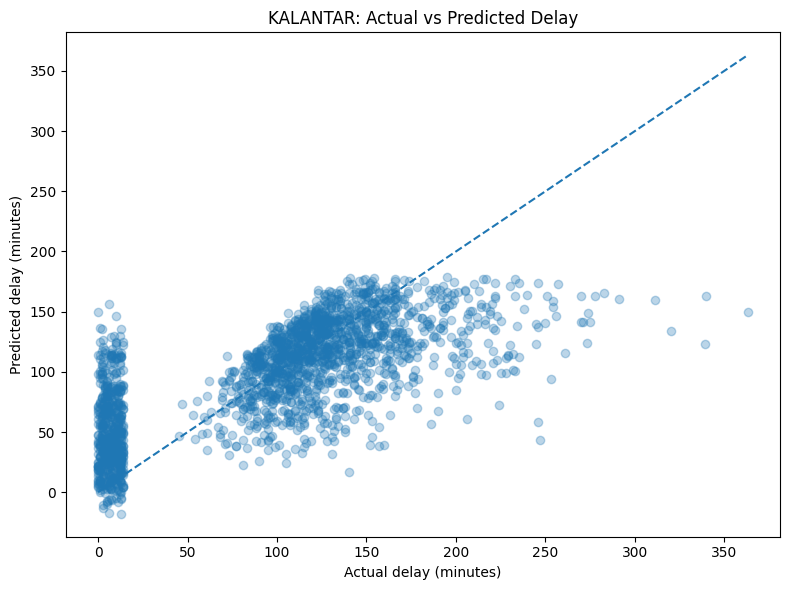

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Compare a small random sample for visualization
rng = np.random.default_rng(42)
sample_size = min(2000, len(y_val))
indices = rng.choice(len(y_val), size=sample_size, replace=False)

actual_sample = y_val.iloc[indices]
predicted_sample = predictions[indices]

plt.figure(figsize=(8, 6))
plt.scatter(actual_sample, predicted_sample, alpha=0.3)

max_value = max(actual_sample.max(), predicted_sample.max())
plt.plot([0, max_value], [0, max_value], linestyle="--")

plt.xlabel("Actual delay (minutes)")
plt.ylabel("Predicted delay (minutes)")
plt.title("KALANTAR: Actual vs Predicted Delay")
plt.tight_layout()
plt.show()

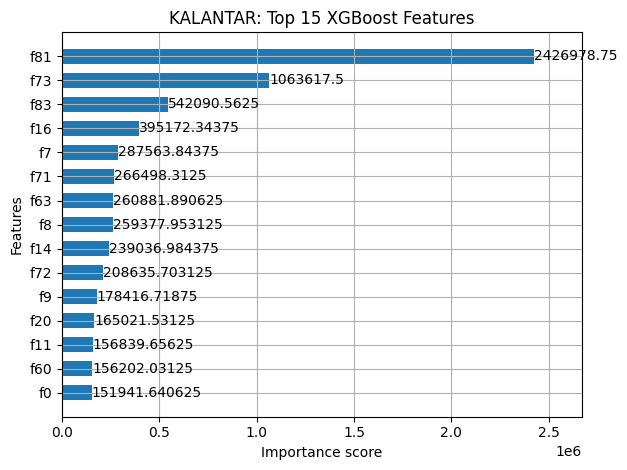

In [4]:
from xgboost import plot_importance

plot_importance(
    model,
    max_num_features=15,
    importance_type="gain",
    height=0.6
)

plt.title("KALANTAR: Top 15 XGBoost Features")
plt.tight_layout()
plt.show()

In [5]:
from pathlib import Path

Path("../docs").mkdir(parents=True, exist_ok=True)

results = f"""
KALANTAR — Experiment 002
Model: XGBoost Regressor
Dataset: Synthetic railway delay dataset
Training sample: {len(y_train)}
Validation sample: {len(y_val)}

Validation MAE: {mean_absolute_error(y_val, predictions):.2f} minutes
Validation RMSE: {np.sqrt(mean_squared_error(y_val, predictions)):.2f} minutes

Sampled validation median baseline MAE:
{mean_absolute_error(y_val, np.full(len(y_val), y_train.median())):.2f} minutes
"""

Path("../docs/experiment_002.txt").write_text(
    results,
    encoding="utf-8"
)

print(results)


KALANTAR — Experiment 002
Model: XGBoost Regressor
Dataset: Synthetic railway delay dataset
Training sample: 75000
Validation sample: 30000

Validation MAE: 34.65 minutes
Validation RMSE: 46.91 minutes

Sampled validation median baseline MAE:
52.65 minutes



In [6]:
# Map XGBoost's encoded feature indices back to feature names

encoded_feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "encoded_feature": encoded_feature_names,
    "importance_gain": model.feature_importances_
})

importance = importance.sort_values(
    "importance_gain",
    ascending=False
)

print("Top 20 features:")
print(importance.head(20).to_string(index=False))

Top 20 features:
                     encoded_feature  importance_gain
             num__late_incoming_rake         0.277346
          num__season_severity_score         0.121546
    num__route_historical_ontime_pct         0.061948
                 cat__season_Monsoon         0.045159
        cat__train_type_Mail/Express         0.032862
                 num__zone_fog_index         0.030454
                  num__track_doubled         0.029813
     cat__train_type_Passenger Train         0.029641
cat__train_type_Vande Bharat Express         0.027316
          num__zone_congestion_index         0.023842
    cat__train_type_Rajdhani Express         0.020389
              cat__season_Winter/Fog         0.018858
    cat__train_type_Shatabdi Express         0.017923
                    num__distance_km         0.017850
           cat__train_type_DEMU/MEMU         0.017363
       cat__train_type_Tejas Express         0.010324
                    num__is_fog_risk         0.010208
           

In [7]:
# Evaluate prediction errors across actual-delay groups

evaluation = pd.DataFrame({
    "actual_delay": y_val.to_numpy(),
    "predicted_delay": predictions
})

evaluation["absolute_error"] = (
    evaluation["actual_delay"] -
    evaluation["predicted_delay"]
).abs()

evaluation["delay_group"] = pd.cut(
    evaluation["actual_delay"],
    bins=[-1, 0, 15, 60, 120, 180, 300, float("inf")],
    labels=[
        "On time (0)",
        "1–15 min",
        "16–60 min",
        "61–120 min",
        "121–180 min",
        "181–300 min",
        "Over 300 min"
    ]
)

group_results = evaluation.groupby(
    "delay_group",
    observed=False
).agg(
    journeys=("actual_delay", "size"),
    mean_actual_delay=("actual_delay", "mean"),
    mean_predicted_delay=("predicted_delay", "mean"),
    MAE=("absolute_error", "mean")
).round(2)

print(group_results)

              journeys  mean_actual_delay  mean_predicted_delay     MAE
delay_group                                                            
On time (0)        562               0.00             49.799999   50.54
1–15 min          7918               7.49             50.299999   44.23
16–60 min           86              54.90             52.060001   17.01
61–120 min        9020             100.68            100.099998   20.35
121–180 min      10003             143.68            128.009995   27.74
181–300 min       2329             210.38            132.240005   78.14
Over 300 min        82             334.34            136.139999  198.20


In [8]:
# Compare target delays for the incoming-rake indicator

print(
    train_df.groupby("late_incoming_rake")["delay_minutes"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print("\nMean delay by season:")
print(
    train_df.groupby("season", observed=False)["delay_minutes"]
    .agg(["count", "mean", "median"])
    .round(2)
)

                    count    mean  median    std
late_incoming_rake                              
0                   48809   80.19    95.0  62.79
1                   26191  129.95   136.0  59.39

Mean delay by season:
              count    mean  median
season                             
Autumn         6012   67.98    68.5
Monsoon       24975  126.22   126.0
Post-Monsoon   6394   78.56    92.0
Pre-Monsoon    6298   72.46    84.0
Summer        12600   65.12    14.0
Winter/Fog    18721  105.61   116.0


In [10]:

# Inspect the longest delays using only available columns

extreme = train_df.nlargest(20, "delay_minutes")

columns_to_inspect = [
    "train_type",
    "season",
    "late_incoming_rake",
    "season_severity_score",
    "route_historical_ontime_pct",
    "distance_km",
    "scheduled_travel_hours",
    "delay_minutes",
]

# Keep only columns available in this dataframe
columns_to_inspect = [
    col for col in columns_to_inspect
    if col in extreme.columns
]

print(extreme[columns_to_inspect].to_string(index=False))


        train_type       season  late_incoming_rake  season_severity_score  route_historical_ontime_pct  distance_km  scheduled_travel_hours  delay_minutes
      Mail/Express   Winter/Fog                   1                   0.78                         73.8          328                    6.31            472
      Mail/Express      Monsoon                   1                   0.90                         52.6          864                   16.62            450
   Passenger Train      Monsoon                   1                   0.88                         50.0          211                    5.55            428
         DEMU/MEMU Post-Monsoon                   1                   0.42                         70.3          214                    5.10            425
   Passenger Train      Monsoon                   1                   0.90                         49.0          325                    8.55            423
      Mail/Express      Monsoon                   1             

In [11]:
# Positive residual = model underpredicted the delay
# Negative residual = model overpredicted the delay

diagnostics = pd.DataFrame({
    "actual": y_val.to_numpy(),
    "predicted": predictions,
})

diagnostics["residual"] = (
    diagnostics["actual"] - diagnostics["predicted"]
)

print("Mean residual:", round(diagnostics["residual"].mean(), 2))
print("Median residual:", round(diagnostics["residual"].median(), 2))

print("\nResidual summary by actual-delay range:")

diagnostics["delay_range"] = pd.cut(
    diagnostics["actual"],
    bins=[-1, 0, 15, 60, 120, 180, 300, float("inf")],
    labels=[
        "0",
        "1–15",
        "16–60",
        "61–120",
        "121–180",
        "181–300",
        "Over 300",
    ],
)

print(
    diagnostics.groupby("delay_range", observed=False)["residual"]
    .agg(["count", "mean", "median"])
    .round(2)
)

Mean residual: -0.22
Median residual: -5.09

Residual summary by actual-delay range:
             count    mean  median
delay_range                       
0              562  -49.80  -47.84
1–15          7918  -42.82  -38.93
16–60           86    2.84    4.01
61–120        9020    0.58   -4.44
121–180      10003   15.67   10.71
181–300       2329   78.14   74.37
Over 300        82  198.20  186.17
